## Final fitting of HPK Temperature data (Wlen scans)

nominal pinhole size is 2mm  
nominal wlens is 350-830nm

This notebook includes all the data:

9nm fwhm is negligible

1. Feb 24 2024 - HPK, all wlens
   1. cold - 160K
   2. old data
      1. veraData/HPK_IR_PDE_feb24_stat_error_only.csv - different processing we believe
      2. HPK_IR_PDE-Feb12_2024-Harry - has angles as well
   3. this was actually reprocessed with different QA data. new data to use is
      1. HPK_PDE_sept24.csv
   4. __only analyzing this data__
2. June/July 2024
   1. various temperatures (-80 to -40)
   2. veraData/angular_scans_VUV_feb2024/*
   3. for next analysis

------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


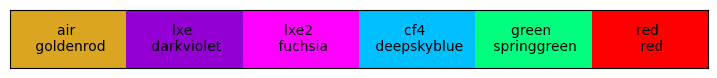

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d
import time

from scipy import optimize as opt
from scipy import stats as sps
import iminuit
from iminuit import Minuit
from iminuit.cost import LeastSquares

import uproot

import json

import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PDEModel import PNJunction as PNJ

import FittingTools.FittingFunctions as FF
from FittingTools.FittingFunctions import *

import FittingTools.PDE_fittingTools as SS

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

rad2deg = 180/np.pi

---
---
## Parameters shared by everything

In [3]:
dhFranta = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
fixedPars_Boring = {"quantum": False, "smoothSigma": 10, "dh":dhFranta, "window":True}

with open("input_systematics.json", 'r') as file:
    json_systematic = json.load(file)

FF1 = json_systematic["HPK_VUV4"]["input_systematics"]["FF"]
ttGood = json_systematic["HPK_VUV4"]["input_systematics"]["tOxide"][0]
print(FF1, ttGood)

fitDict = json_systematic["HPK_VUV4"]["fit_parameters"]
fitVal_dict = {key: value[0] for key, value in fitDict.items()}
fitErr_dict = {key: value[1] for key, value in fitDict.items()}
print(fitVal_dict)

fixedPars_physics = {"FF": 0.55, "tOxide":ttGood, "Ae":1.0, "Ah":1.0,}
fixedPars_parametrized = {**fitVal_dict}
# fixedPars_parametrized["dp_star"] = 15

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-150K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
0.6 16.8
{'dp_star': 1.407, 'Xpn': 2318.8184, 'dw_star': 13299.2962, 'Ve': 1.7648, 'Vh': 16.1748}


---
### Loading Data

['Wavelength' 'Angle' 'Overvoltage' 'Resp' 'PDE' 'PDE_error']
voltages: [1 2 3 4 5 6 7 8]
['Wavelength' 'Angle' 'Overvoltage' 'Responsivity' 'PDE' 'PDE_error']
voltages: [2.044 4.09  6.13 ]
['Wavelength' 'Angle' 'Overvoltage' 'Responsivity' 'PDE' 'PDE_error']
voltages: [2.074 4.15  6.22 ]
['Wavelength' 'Angle' 'Overvoltage' 'Responsivity' 'PDE' 'PDE_error']
voltages: [2.23 4.35 6.48]
root voltages: [2.16999893 4.32999878 6.50000076]


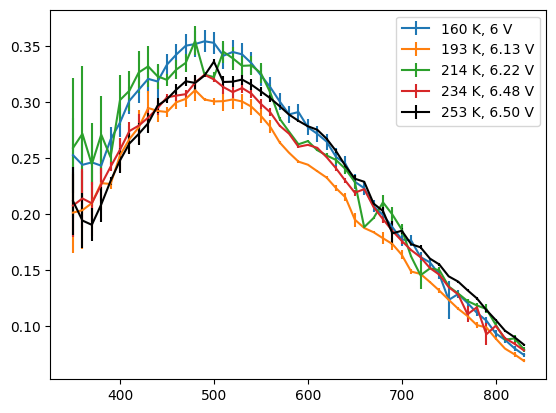

In [4]:
temps = [160, 193, 214, 234, 253]
fpath1 = os.path.join(VERA_DATA_PATH, "HPK_PDE_sept24.csv")
fpath2 = os.path.join(VERA_DATA_PATH, "HPK_tempScans", "HPKW_IR_PDE_stat_error_only_193K.csv")
fpath3 = os.path.join(VERA_DATA_PATH, "HPK_tempScans", "HPKW_IR_PDE_stat_error_only_214K.csv")
fpath4 = os.path.join(VERA_DATA_PATH, "HPK_tempScans", "HPKW_IR_PDE_stat_error_only_234K.csv")
fpath5 = os.path.join(VERA_DATA_PATH, "HPK_tempScans", "HPKW_PDE_253K_stat_error_only.root")
files = [fpath1, fpath2, fpath3, fpath4]

voltage = []
pde_data = []
indV = 2
for temp, fp in zip(temps, files):
    df = pd.read_csv(fp, header=0)
    print(df.columns.values)
    
    voltages = df["Overvoltage"].unique()
    print("voltages:", voltages)
    vPick = 6 if temp == 160 else voltages[indV]
    voltage.append(vPick)
    dfFiltered = df[df["Overvoltage"] == vPick]
    
    pde_data.append([dfFiltered['Wavelength'].values, dfFiltered['PDE'].values, dfFiltered['PDE_error'].values])
    plt.errorbar(dfFiltered['Wavelength'], dfFiltered['PDE'], yerr=dfFiltered['PDE_error'], label=f"{temp} K, {vPick} V")

rFile = uproot.open(fpath5)
ttree = rFile["Resp_Output"]
df_ttree = ttree.arrays(library="pd")
# print(df_ttree.head())
rootVoltages = df_ttree["outOvervoltage"].unique()

print("root voltages:", rootVoltages)
dfVolt = df_ttree[df_ttree["outOvervoltage"] == rootVoltages[indV]]
plt.errorbar(dfVolt['outWavelength'], dfVolt['outPDE'], yerr=dfVolt['outPDE_error'], label=f"253 K, {rootVoltages[indV]:0.2f} V", color='black')
pde_data.append([dfVolt['outWavelength'].values, dfVolt['outPDE'].values, dfVolt['outPDE_error'].values])
voltage.append(rootVoltages[indV])
plt.legend()
plt.show()

temperature scaling not tested/validated below 300nm, be careful
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.
temperature scaling not tested/validated below 300nm, be careful
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.
temperature scaling not tested/validated below 300nm, be careful
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.
temperature scaling not tested/validated below 300nm, be careful
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.
temperature scaling not tested/validated below 300nm, be careful
temperature scaling not tested/validated below 300nm, be careful
temperature scaling not tested/validated below 300nm, be careful
temperature scaling not tested/validated below 300nm, be careful


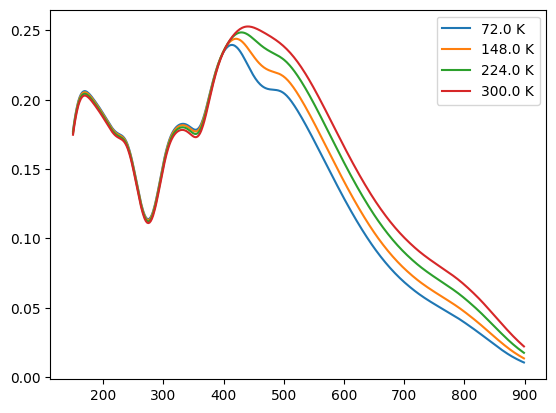

In [ ]:
tempScan = np.linspace(72, 300, 4)

parDict = {**fixedPars_parametrized, **fixedPars_physics, **fixedPars_Boring}

xwlen = np.arange(150, 900, 1)
for T in tempScan:
    yPDE = FF.PDE_allArgs_wlen_parametrized(wlen=xwlen, theta1 = 0, voltage = 3, Temperature=T, **parDict)
    plt.plot(xwlen, yPDE, label=f"{T} K")
# xwlen = np.arange(150, 900, 1)
# yPDE = FF.PDE_allArgs_wlen_parametrized(wlen=xwlen, theta1 = 0, voltage = 3, Temperature=160, **parDict)
# plt.plot(xwlen, yPDE, label="160 K")
plt.legend()


Temperature: 193 K, Voltage: 6.13 V
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


NameError: name 'chi2' is not defined

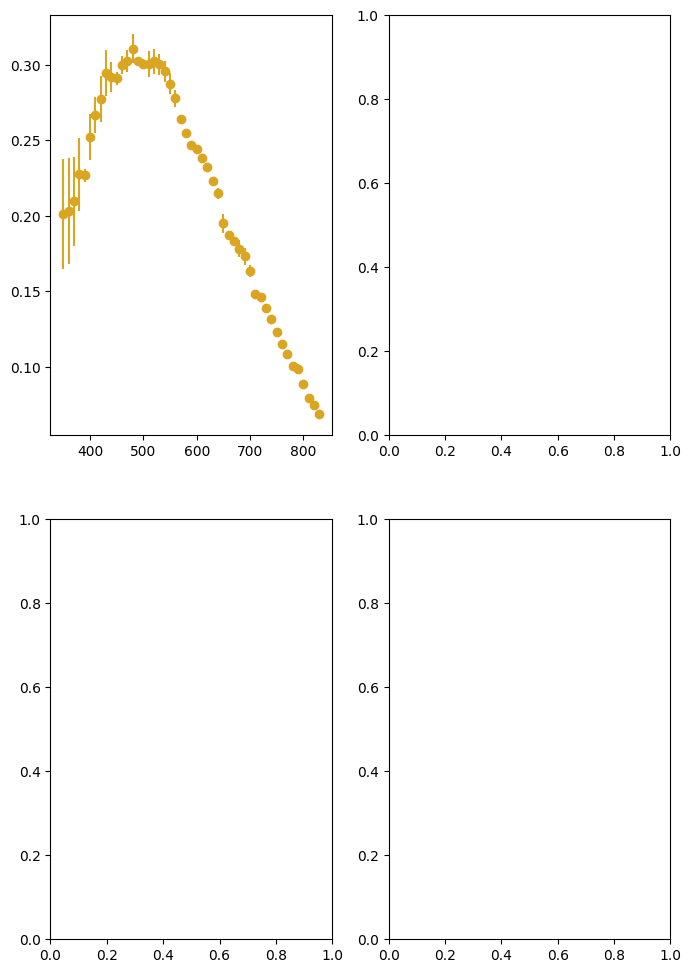

In [ ]:
wlens = np.arange(350, 830, 2)
import copy

# fixedPars_parametrized["Xpn"] *= 0.6
# fixedPars_parametrized["dw_star"] *= 1.2
ms.ResetColorCycle()

def chi2_red(y, yerr, fit, nFree):
    return np.sum((y - fit)**2 / yerr**2) / (len(y) - nFree)

fig, axes = plt.subplots(2, 2, figsize=(8, 12))
axes = axes.flatten()

for T, V, PDE, ax in zip(temps[1:], voltage[1:], pde_data[1:], axes):
    color = ms.GetNextColor()

    xwlen = PDE[0]
    yPDE = PDE[1]
    yPDEerr = PDE[2]
    ax.errorbar(PDE[0], PDE[1], yerr=PDE[2], label=f"{T} K, {V} V", fmt='o', color=color)
    
    ## all inputs
    print(f"\nTemperature: {T} K, Voltage: {V} V")
    allFuncArgs = {"theta1": 0, "voltage": V, "Temperature":T, **fixedPars_physics, **fixedPars_parametrized}
    
    # plot the guess
    yPDE = FF.PDE_allArgs_wlen_parametrized(wlen = PDE[0], **allFuncArgs)
    #chi2 of guess
    chi2_guess = chi2_red(PDE[1], PDE[2], yPDE, 1)
    print("chi2 of guess:", chi2)
    # plt.plot(PDE[0], yPDE, color=color)
    
    ########## only floating the front of the junction
    fixed1 = copy.deepcopy(allFuncArgs)
    fixed1.pop("dp_star")
    def model_function_1(wlen, dp_star):
        return FF.PDE_allArgs_wlen_parametrized(wlen=wlen, dp_star=dp_star, **fixed1)

    # Create a LeastSquares cost function
    maskBelow500 = PDE[0] < 400
    least_squares = LeastSquares(PDE[0][maskBelow500], PDE[1][maskBelow500], PDE[2][maskBelow500], model_function_1)
    
    # Initial value for the parameter to fit
    initial_value = {'dp_star':1.0}
    
    # Create a Minuit object with the cost function and initial value
    m = Minuit(least_squares, **initial_value)
    # m.fixed['tOxide'] = True
    # m.limits['tOxide'] = (5, 50)
    m.limits['dp_star'] = (0.01, 20)
    
    # Perform the minimization
    result = m.migrad()#iterate=True, use_simplex=True)
    print("fit chi2", result.fval)
    
    resultCurve = model_function_1(PDE[0], dp_star=m.values['dp_star'])
    result_chi2 = chi2_red(PDE[1], PDE[2], resultCurve, len(initial_value))
    
    print("dp fit: {:.2f}".format(m.values['dp_star']))
    print("fit chi2 full", result_full.fval)
    
    ax.plot(PDE[0], resultCurve, color=color, linestyle='--')
    # plt.plot(PDE[0], model_function_1(PDE[0], dp_star=50), color=color, linestyle='--')

    print("-------full fit----")
    ########### full junction fit ###########
    fixed_full = copy.deepcopy(allFuncArgs)
    fixed_full.pop("dp_star")
    fixed_full.pop("Xpn")
    fixed_full.pop("dw_star")
    def model_function_full(wlen, dp_star, Xpn, dw_star):
        return FF.PDE_allArgs_wlen_parametrized(wlen=wlen, dp_star=dp_star, Xpn=Xpn, dw_star=dw_star, **fixed_full)
    
    least_squares_full = LeastSquares(PDE[0], PDE[1], PDE[2], model_function_full)
    initial_value_full = {'dp_star':2.8, 'Xpn':fitVal_dict["Xpn"], 'dw_star':fitVal_dict["dw_star"]}
    
    mfull = Minuit(least_squares_full, **initial_value_full)
    mfull.limits['dp_star'] = (0.01, 5)
    mfull.fixed['dp_star'] = True
    mfull.limits['Xpn'] = (0.6*fitVal_dict["Xpn"], 1.4*fitVal_dict["Xpn"])
    mfull.limits['dw_star'] = (0.6*fitVal_dict["dw_star"], 1.4*fitVal_dict["dw_star"])
    
    result_full = mfull.migrad()
    # print(result_full.values)
    resultfull = model_function_full(PDE[0], dp_star=mfull.values['dp_star'], Xpn=mfull.values['Xpn'], dw_star=mfull.values['dw_star'])
    result_chi2_full = chi2_red(PDE[1], PDE[2], resultfull, len(initial_value_full))
    print("full fit chi2", result_chi2_full)
    print("dp fit: {:.2f}, Xpn fit: {:.2f}, dw_star fit: {:.2f}".format(mfull.values['dp_star'], mfull.values['Xpn'], mfull.values['dw_star']))
    ax.plot(PDE[0], resultfull, color=color, linestyle=':')
    
    fitPars = "chi2red = {:.2f}\ndp: {:.2f}, Xpn: {:.0f}, dw_star: {:.0f}".format(result_chi2_full, mfull.values['dp_star'], mfull.values['Xpn'], mfull.values['dw_star'])
    ax.text(400, 0.1, fitPars, fontsize=8, bbox=dict(facecolor='white', alpha=0.5))
    ax.set_title(f"{T} K")

plt.legend()

# print(len(pde_data))



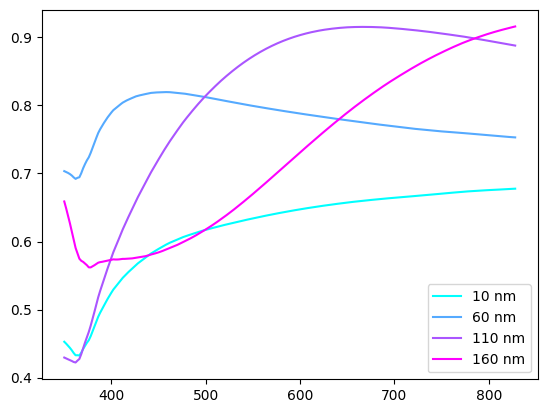

In [6]:
# thickness = np.arange(10, 1000, 200)
thickness = np.arange(10, 200, 50)
photon = PhotonInfo(wlen=400, theta_1=0)
from cycler import cycler
plt.rc('axes', prop_cycle=cycler(color=plt.cm.cool(np.linspace(0, 1, len(thickness)))))

wlens = np.arange(350, 830, 2)
photon = PhotonInfo(wlen=wlens, theta_1=0)

# plt.plot(thickness, photon.Wave_TotalTransmission(thickness), label="400 nm")
for thick in thickness:
    
    plt.plot(wlens, photon.Wave_TotalTransmission(thick), label=f"{thick} nm")
# plt.plot(wlens, photon.Wave_TotalTransmission(), label="400 nm")
plt.legend()


0.266186375 1.1435159857449506
0.304679125 0.9990457173592056
0.27306981249999995 1.1146906800618985
0.2689233914090584 1.1318776451729182


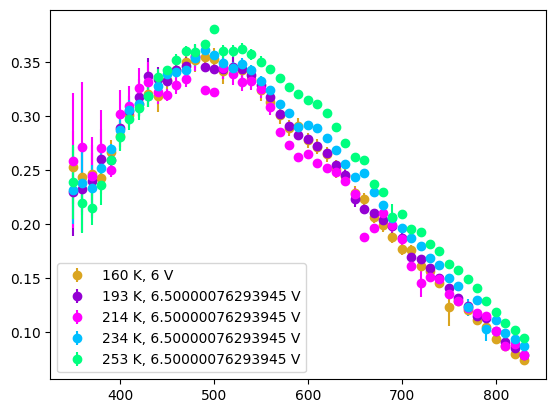

In [7]:
## Try scaling the data below 500nm so the average is equal to the average above 500nm

scaling = [1.0]
ms.SetMPLcolors()
def GetMean_belowVal(x, y, val):
    ind = np.where(x < val)
    return np.mean(y[ind])

mean160 = GetMean_belowVal(pde_data[0][0], pde_data[0][1], 500)

plt.errorbar(pde_data[0][0], pde_data[0][1], yerr=pde_data[0][2], fmt='o', label="160 K, 6 V")
for PDE, temp in zip(pde_data[1:], temps[1:]):
    xwlen = PDE[0]
    yPDE = PDE[1]
    yPDEerr = PDE[2]
    mean = GetMean_belowVal(xwlen, yPDE, 500)
    scaling = mean160/mean
    print(mean, scaling)
    plt.errorbar(xwlen, yPDE*scaling, yerr=yPDEerr*scaling, fmt='o', label=f"{temp} K, {V} V")


plt.legend()
plt.show()